In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load dataset
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five records:")
print(df.head())

Dataset loaded successfully!
Dataset shape: (20640, 9)

First five records:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [2]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nSummary statistics:")
print(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

Number of rows: 20640
Number of columns: 9

Column names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Data types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Summary statistics:
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333333      3.000000   
25%        2.563400     18.000000      4.440716      1.006079    787.000000   
50%        3.534800     29.000000      5.229129      1.048780   1166.000000   
75%        4.743250 

In [3]:
# Remove duplicate records if any
df = df.drop_duplicates()

# Handle missing values in numeric columns
df = df.fillna(df.median(numeric_only=True))

# Select input and target
X = df[["MedInc"]]
y = df["MedHouseVal"]

print("Input feature: MedInc")
print("Target variable: MedHouseVal")
print("Missing values after cleaning:", df.isnull().sum().sum())

print("\nInput sample:")
print(X.head())

print("\nTarget sample:")
print(y.head())

Input feature: MedInc
Target variable: MedHouseVal
Missing values after cleaning: 0

Input sample:
   MedInc
0  8.3252
1  8.3014
2  7.2574
3  5.6431
4  3.8462

Target sample:
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64


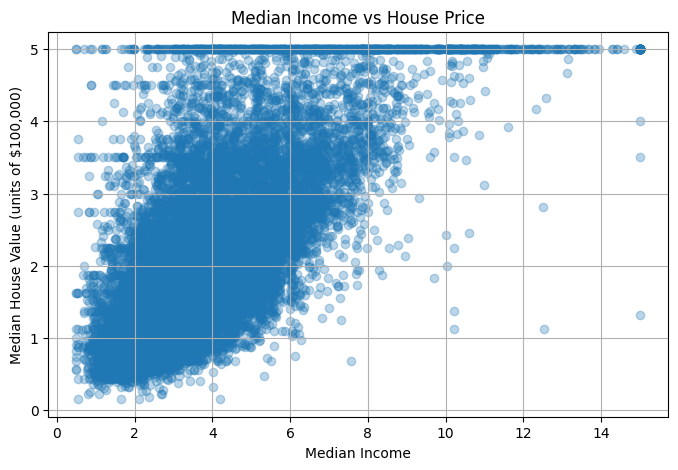

In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(X["MedInc"], y, alpha=0.3)

plt.title("Median Income vs House Price")
plt.xlabel("Median Income")
plt.ylabel("Median House Value (units of $100,000)")
plt.grid(True)
plt.show()

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

# Train Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

print("\nIntercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

print("\nRegression equation:")
print(f"House Price = {model.intercept_:.4f} + "
      f"({model.coef_[0]:.4f} * Median Income)")

Training observations: 16512
Testing observations: 4128

Intercept: 0.4445972916907879
Coefficient: 0.4193384939381271

Regression equation:
House Price = 0.4446 + (0.4193 * Median Income)


In [6]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Price": y_test.values[:10],
    "Predicted Price": y_pred[:10]
})

print(comparison.round(3))

   Actual Price  Predicted Price
0         0.477            1.150
1         0.458            1.506
2         5.000            1.904
3         2.186            2.851
4         2.780            2.007
5         1.587            2.422
6         1.982            2.576
7         1.575            1.992
8         3.400            2.459
9         4.466            3.847


In [7]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 4))
print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("R-squared (R2):", round(r2, 4))

Mean Absolute Error (MAE): 0.6299
Mean Squared Error (MSE): 0.7091
Root Mean Squared Error (RMSE): 0.8421
R-squared (R2): 0.4589


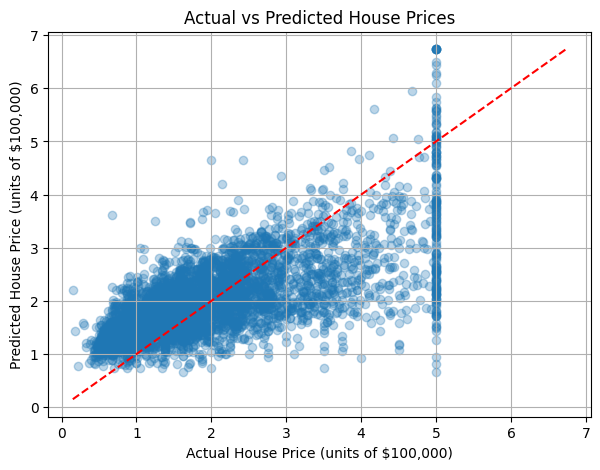

In [8]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred, alpha=0.3)

# Perfect prediction reference line
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot([lower, upper], [lower, upper], "r--")

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual House Price (units of $100,000)")
plt.ylabel("Predicted House Price (units of $100,000)")
plt.grid(True)
plt.show()

In [9]:
# Example: median income value within the dataset's range
new_income = pd.DataFrame({"MedInc": [5.0]})

predicted_price = model.predict(new_income)[0]

print("Median Income:", 5.0)
print("Predicted House Value:", round(predicted_price, 4),
      "units of $100,000")
print("Predicted Price in dollars: $",
      round(predicted_price * 100000, 2))

Median Income: 5.0
Predicted House Value: 2.5413 units of $100,000
Predicted Price in dollars: $ 254128.98


**Conclusion:**

In this activity, I developed a Linear Regression model to predict house prices using the California Housing dataset. I selected median income as the input feature and median house value as the target variable. The dataset was divided into 80% training data and 20% testing data. The model was trained and evaluated using MAE, MSE, RMSE and R². Scatter plots were used to visualize the relationship between income and house value and to compare actual and predicted values. Finally, the trained model was used to predict a new house value.

The model provides a basic estimate of house prices, but its accuracy is limited because property prices also depend on location, house size, age and other factors. Therefore, a single-feature Linear Regression model may not predict every house price accurately.